# California Housing Price Prediction

## Project objective
Build and evaluate regression models to predict the median house value of California districts using demographic and housing features.

**Dataset:** California Housing dataset from scikit-learn.  
**Target:** `MedHouseVal`, expressed in units of **$100,000**. For example, a target value of `2.0` corresponds to approximately $200,000.

We will establish a linear-regression baseline, inspect its errors, compare it with a Random Forest, and interpret the variables used by the final model.

> **Evaluation note:** the test set was used during the exploratory comparisons in this notebook. The reported test scores are useful for this learning project, but they should not be treated as a completely untouched final evaluation. For a stricter assessment, select models using cross-validation and evaluate the chosen model on the test set only once.

## 1. Imports and data loading

In [7]:

import pandas as pd
import numpy as np
import zipfile
import io
import urllib.request

#  California Housing dataset
url = "https://lib.stat.cmu.edu/datasets/houses.zip"

with urllib.request.urlopen(url, timeout=30) as response:
    zip_data = response.read()

# Read the data file from the ZIP archive
with zipfile.ZipFile(io.BytesIO(zip_data)) as archive:
    with archive.open("cadata.txt") as file:
        lines = file.read().decode("latin-1").splitlines()

# Keep the data rows and combine the wrapped lines
data_lines = [line.strip() for line in lines if line.startswith(" ")]
data = np.loadtxt(io.StringIO("\n".join(data_lines)))

# Original columns:
# median house value, median income, housing age,
# total rooms, total bedrooms, population, households,
# latitude, longitude
df = pd.DataFrame(data, columns=[
    "MedHouseVal_raw", "MedInc", "HouseAge",
    "AveRooms_raw", "AveBedrms_raw", "Population",
    "Households", "Latitude", "Longitude"
])

# Reproduce scikit-learn's feature calculations
df["AveRooms"] = df["AveRooms_raw"] / df["Households"]
df["AveBedrms"] = df["AveBedrms_raw"] / df["Households"]
df["AveOccup"] = df["Population"] / df["Households"]
df["MedHouseVal"] = df["MedHouseVal_raw"] / 100000

# Keep the same 8 features and target as our original project
feature_names = [
    "MedInc", "HouseAge", "AveRooms", "AveBedrms",
    "Population", "AveOccup", "Latitude", "Longitude"
]

df = df[feature_names + ["MedHouseVal"]]

# Verify the dataset
assert df.shape == (20640, 9), f"Unexpected shape: {df.shape}"
assert not df.isna().any().any(), "Missing values detected"

print("Dataset loaded")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded
Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Explore and prepare the data

Each row represents a California district. The features are numeric summaries of housing and population in that district; they are not measurements of an individual house.

In [8]:
print("Data types and non-null values:")
df.info()

print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_values"))

print("\nTarget summary:")
display(df["MedHouseVal"].describe())

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values per column:


,missing_values
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0



Target summary:


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


In [9]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

print("Features:", X.shape)
print("Target:", y.shape)
print("Feature names:", X.columns.tolist())

Features: (20640, 8)
Target: (20640,)
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


### Train/test split

We keep 20% of the observations for testing and train the models on the remaining 80%. `random_state=42` makes the split reproducible.

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (16512, 8)
Test set: (4128, 8)


## 3. Linear regression baseline

Linear regression estimates coefficients that minimize the sum of squared residuals on the training data.

We evaluate predictions using:
- **R²:** improvement over predicting the test-set mean, expressed as a proportion of the target variation.
- **RMSE:** typical error magnitude in the target's units; lower is better.

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

def regression_metrics(y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {
        "R²": r2_score(y_true, y_pred),
        "RMSE (target units)": rmse,
        "RMSE (approx. dollars)": rmse * 100_000,
    }

linear_metrics = regression_metrics(y_test, linear_pred)
display(pd.Series(linear_metrics, name="Linear Regression"))

,Linear Regression
R²,0.575788
RMSE (target units),0.745581
RMSE (approx. dollars),74558.138301


In [12]:
coefficients = pd.Series(
    linear_model.coef_, index=X_train.columns
).sort_values(key=abs, ascending=False)

print(f"Intercept: {linear_model.intercept_:.4f}")
display(coefficients.to_frame("coefficient"))

Intercept: -37.0233


,coefficient
AveBedrms,0.783145
MedInc,0.448675
Longitude,-0.433708
Latitude,-0.419792
AveRooms,-0.123323
HouseAge,0.009724
AveOccup,-0.003526
Population,-0.000002


### Actual values vs predictions

Points near the dashed diagonal are predictions close to the actual values. Systematic departures from the diagonal indicate errors the model may not capture.

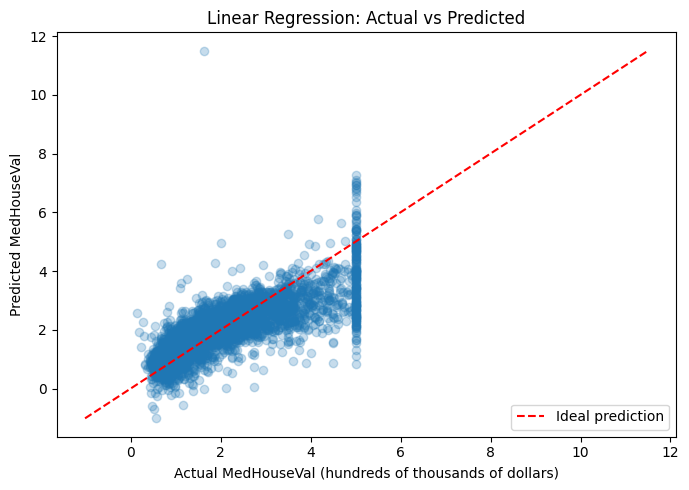

In [13]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, linear_pred, alpha=0.25)
limits = [
    min(y_test.min(), linear_pred.min()),
    max(y_test.max(), linear_pred.max())
]
plt.plot(limits, limits, "r--", label="Ideal prediction")
plt.xlabel("Actual MedHouseVal (hundreds of thousands of dollars)")
plt.ylabel("Predicted MedHouseVal")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

### Residual analysis

A residual is `actual - predicted`. The plot helps reveal patterns, unusually large errors, or systematic bias. Residuals are diagnostic evidence, not an automatic reason to remove observations.

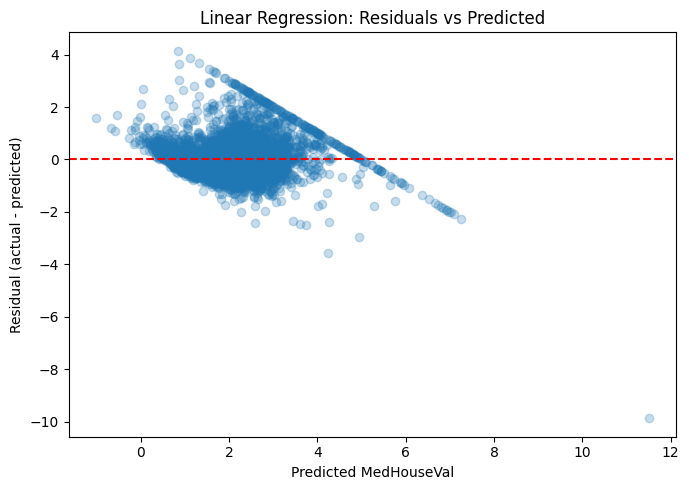

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Residual,Absolute_Error
1979,4.6250,34.0,132.533333,34.066667,36.0,2.400000,38.80,-120.08,1.62500,11.500331,-9.875331,9.875331
6688,0.4999,28.0,7.677419,1.870968,142.0,4.580645,34.15,-118.08,5.00001,0.851622,4.148388,4.148388
10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.115227,3.884783,3.884783
12389,3.7727,24.0,10.953586,1.848101,473.0,1.995781,33.75,-116.43,5.00001,1.319954,3.680056,3.680056
19542,1.7679,39.0,5.000000,0.888889,22.0,2.444444,37.63,-120.92,4.50000,0.867216,3.632784,3.632784
4548,7.5752,52.0,3.142857,1.000000,55.0,7.857143,34.02,-118.21,0.67500,4.236215,-3.561215,3.561215
459,1.1696,52.0,2.436000,0.944000,1349.0,5.396000,37.87,-122.25,5.00001,1.547530,3.452480,3.452480
15652,0.9000,52.0,2.237474,1.053535,3260.0,2.237474,37.80,-122.41,5.00001,1.642870,3.357140,3.357140
12069,4.2386,6.0,7.723077,1.169231,228.0,3.507692,33.83,-117.55,5.00001,1.668034,3.331976,3.331976
4630,2.3674,20.0,2.740554,1.047859,2919.0,2.450882,34.07,-118.31,5.00001,1.711156,3.288854,3.288854


In [14]:
linear_residuals = y_test - linear_pred

plt.figure(figsize=(7, 5))
plt.scatter(linear_pred, linear_residuals, alpha=0.25)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted MedHouseVal")
plt.ylabel("Residual (actual - predicted)")
plt.title("Linear Regression: Residuals vs Predicted")
plt.tight_layout()
plt.show()

error_table = X_test.copy()
error_table["Actual"] = y_test
error_table["Predicted"] = linear_pred
error_table["Residual"] = linear_residuals
error_table["Absolute_Error"] = linear_residuals.abs()

display(error_table.sort_values("Absolute_Error", ascending=False).head(10))

### Inspecting extreme `AveRooms` values

The IQR rule is a way to flag unusually high values in a feature. A flagged value is not necessarily wrong, so we inspect it rather than deleting it automatically.

In [15]:
q1 = X_train["AveRooms"].quantile(0.25)
q3 = X_train["AveRooms"].quantile(0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

high_rooms = X_train[X_train["AveRooms"] > upper_bound]

print(f"Median AveRooms: {X_train['AveRooms'].median():.2f}")
print(f"IQR upper bound: {upper_bound:.2f}")
print(f"Rows above the bound: {len(high_rooms)} "
      f"({len(high_rooms) / len(X_train) * 100:.2f}% of training data)")

display(high_rooms.join(y_train).sort_values("AveRooms", ascending=False).head(10))

Median AveRooms: 5.24
IQR upper bound: 8.47
Rows above the bound: 371 (2.25% of training data)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
1914,1.8750,33.0,141.909091,25.636364,30.0,2.727273,38.91,-120.10,5.00001
12447,1.6154,17.0,62.422222,14.111111,83.0,1.844444,33.97,-114.49,0.87500
1913,4.0714,19.0,61.812500,11.000000,112.0,2.333333,39.01,-120.06,4.37500
11862,2.6250,25.0,59.875000,15.312500,28.0,1.750000,40.27,-121.25,0.67500
1912,4.9750,16.0,56.269231,10.153846,54.0,2.076923,39.01,-120.16,2.06300
9676,3.2431,14.0,52.848214,11.410714,265.0,2.366071,37.64,-119.02,2.21400
11707,1.1912,22.0,52.690476,8.857143,98.0,2.333333,39.15,-120.06,1.70000
2395,3.8750,23.0,50.837838,10.270270,64.0,1.729730,37.12,-119.34,1.25000
1240,3.1250,11.0,47.515152,11.181818,82.0,2.484848,38.42,-120.19,0.77500
1872,2.4917,27.0,38.840909,9.272727,97.0,2.204545,38.94,-119.93,2.00000


## 4. Statistical inference with OLS (optional course connection)

This section connects the predictive model to regression inference. The global F-test assesses whether the slope coefficients are jointly zero under the model assumptions. Individual p-values assess each coefficient conditional on the other predictors.

These tests do **not** by themselves tell us which model predicts best on unseen data. Statistical inference and predictive performance answer different questions.

In [16]:
import statsmodels.api as sm

ols_model = sm.OLS(y_train, sm.add_constant(X_train)).fit()

print(f"Global F-statistic: {ols_model.fvalue:.2f}")
print(f"Global F-test p-value: {ols_model.f_pvalue:.3g}")

Global F-statistic: 3261.38
Global F-test p-value: 0


In [17]:
# Review coefficient estimates, confidence intervals and p-values.
display(ols_model.summary())

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            MedHouseVal   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.612
Method:                 Least Squares   F-statistic:                     3261.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        23:00:17   Log-Likelihood:                -17998.
No. Observations:               16512   AIC:                         3.601e+04
Df Residuals:                   16503   BIC:                         3.608e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -37.0233      0.728    -50.835      0.000     -38.451     -35.596
MedInc         0.4487      0.005     95.697      0.000       0.439       0.458
HouseAge       0.0097      0.000     19.665      0.000       0.009       0.011
AveRooms      -0.1233      0.007    -18.677      0.000      -0.136      -0.110
AveBedrms      0.7831      0.033     23.556      0.000       0.718       0.848
Population  -2.03e-06   5.25e-06     -0.387      0.699   -1.23e-05    8.26e-06
AveOccup      -0.0035      0.000     -7.253      0.000      -0.004      -0.003
Latitude      -0.4198      0.008    -52.767      0.000      -0.435      -0.404
Longitude     -0.4337      0.008    -52.117      0.000      -0.450      -0.417
==============================================================================
Omnibus:                     3333.187   Durbin-Watson:                   1.962
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             9371.466
Skew:                           1.071   Prob(JB):                         0.00
Kurtosis:                       6.006   Cond. No.                     2.38e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 2.38e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

## 5. Compare linear feature engineering experiments

We test two simple extensions of linear regression:
- an interaction `MedInc × HouseAge`, allowing the association with one feature to depend on the other;
- a quadratic term `HouseAge²`, allowing curvature in the relationship with house age.

A linear model can still include nonlinear transformations of the inputs while remaining linear in its coefficients.

In [18]:
# Interaction model
X_train_inter = X_train.copy()
X_test_inter = X_test.copy()

X_train_inter["MedInc_HouseAge"] = (
    X_train_inter["MedInc"] * X_train_inter["HouseAge"]
)
X_test_inter["MedInc_HouseAge"] = (
    X_test_inter["MedInc"] * X_test_inter["HouseAge"]
)

interaction_model = LinearRegression().fit(X_train_inter, y_train)
interaction_pred = interaction_model.predict(X_test_inter)

# Quadratic model
X_train_quad = X_train.copy()
X_test_quad = X_test.copy()

X_train_quad["HouseAge_squared"] = X_train_quad["HouseAge"] ** 2
X_test_quad["HouseAge_squared"] = X_test_quad["HouseAge"] ** 2

quadratic_model = LinearRegression().fit(X_train_quad, y_train)
quadratic_pred = quadratic_model.predict(X_test_quad)

comparison = pd.DataFrame({
    "Linear regression": regression_metrics(y_test, linear_pred),
    "Interaction": regression_metrics(y_test, interaction_pred),
    "HouseAge squared": regression_metrics(y_test, quadratic_pred),
}).T

display(comparison)

,R²,RMSE (target units),RMSE (approx. dollars)
Linear regression,0.575788,0.745581,74558.138301
Interaction,0.577091,0.744435,74443.549585
HouseAge squared,0.577972,0.743659,74365.903067


## 6. Random Forest

A Random Forest averages predictions from many decision trees. Unlike ordinary linear regression, it can learn nonlinear relationships and interactions without manually specifying them.

We first fit a default-style forest, then compare it with a constrained forest. The constrained version is a simple regularization experiment; a smaller train/test gap does not guarantee a better test score.

In [19]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_regularized = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_regularized.fit(X_train, y_train)

rf_regularized_pred = rf_regularized.predict(X_test)

model_comparison = pd.DataFrame({
    "Linear regression": regression_metrics(y_test, linear_pred),
    "Interaction": regression_metrics(y_test, interaction_pred),
    "HouseAge squared": regression_metrics(y_test, quadratic_pred),
    "Random Forest": regression_metrics(y_test, rf_pred),
    "Regularized Random Forest": regression_metrics(y_test, rf_regularized_pred),
}).T

display(model_comparison.sort_values("RMSE (target units)"))

,R²,RMSE (target units),RMSE (approx. dollars)
Random Forest,0.805123,0.505340,50533.997737
Regularized Random Forest,0.797363,0.515303,51530.293803
HouseAge squared,0.577972,0.743659,74365.903067
Interaction,0.577091,0.744435,74443.549585
Linear regression,0.575788,0.745581,74558.138301


### Check the train/test gap

A much better training score than test score can indicate overfitting. Here, we compare R² and RMSE for both Random Forest variants.

In [20]:
def train_test_report(fitted_model, model_name):
    pred_train = fitted_model.predict(X_train)
    pred_test = fitted_model.predict(X_test)
    return {
        "Model": model_name,
        "Train R²": r2_score(y_train, pred_train),
        "Test R²": r2_score(y_test, pred_test),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
    }

overfit_comparison = pd.DataFrame([
    train_test_report(rf_model, "Random Forest"),
    train_test_report(rf_regularized, "Regularized Random Forest"),
]).set_index("Model")

display(overfit_comparison)

,Train R²,Test R²,Train RMSE,Test RMSE
Model,,,,
Random Forest,0.973573,0.805123,0.187956,0.505340
Regularized Random Forest,0.907392,0.797363,0.351847,0.515303


## 7. Interpret feature importance

### Impurity-based importance

This measures how much each feature contributes to reductions in tree impurity. It is useful for a first overview, but can be biased and does not establish causation.

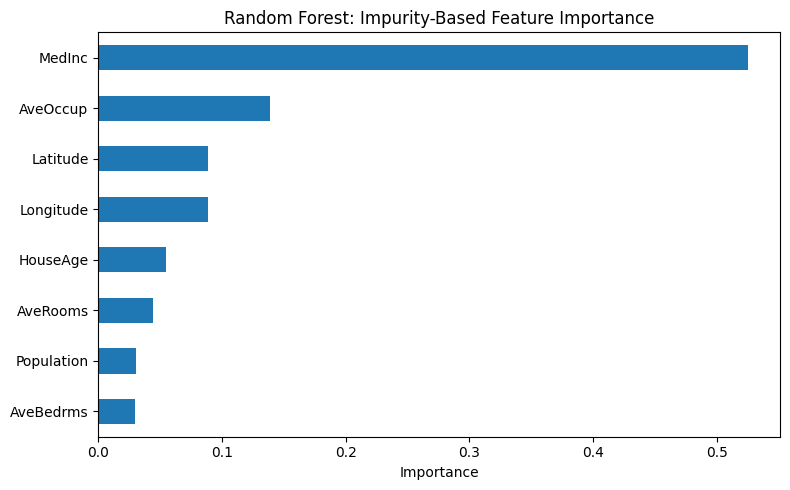

,importance
MedInc,0.524871
AveOccup,0.138443
Latitude,0.088936
Longitude,0.088629
HouseAge,0.054593
AveRooms,0.044272
Population,0.030650
AveBedrms,0.029606


In [21]:
feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values()

feature_importance.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest: Impurity-Based Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

display(feature_importance.sort_values(ascending=False).to_frame("importance"))

### Permutation importance

Permutation importance measures how much the test-set R² falls when the values of one feature are shuffled. A larger drop suggests that the model relies more on that feature. Correlated features can affect one another's scores, so interpret the ranking cautiously.

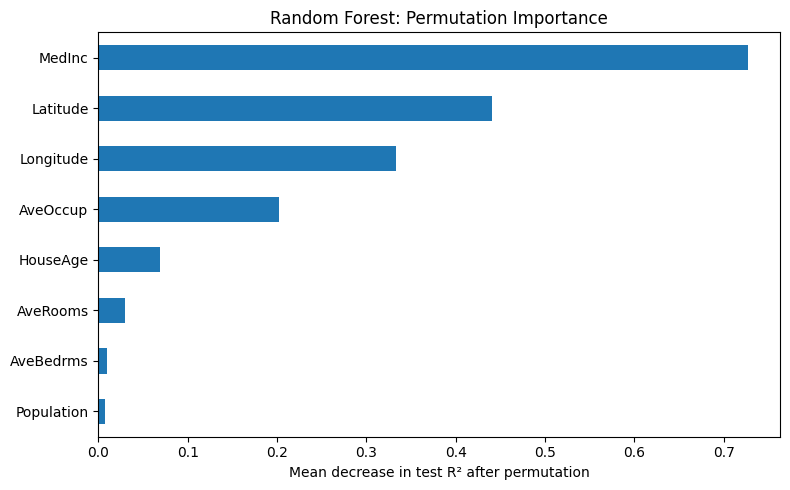

,mean R² decrease
MedInc,0.726760
Latitude,0.440910
Longitude,0.333430
AveOccup,0.201821
HouseAge,0.069346
AveRooms,0.029308
AveBedrms,0.009168
Population,0.007886


In [22]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="r2",
    n_jobs=-1
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=X_test.columns
).sort_values()

perm_importance.plot(kind="barh", figsize=(8, 5))
plt.title("Random Forest: Permutation Importance")
plt.xlabel("Mean decrease in test R² after permutation")
plt.tight_layout()
plt.show()

display(perm_importance.sort_values(ascending=False).to_frame("mean R² decrease"))

## 8. Conclusions and limitations

- The linear regression provides a simple, interpretable baseline.
- The Random Forest performed substantially better on the test split in our experiments.
- The gap between training and test performance suggests that the Random Forest overfits to some degree; the constrained version reduced that gap but did not improve the test score in this experiment.
- `MedInc`, `Latitude` and `Longitude` were among the most informative features in the permutation-importance analysis.
- Extreme feature values were inspected rather than automatically removed.
- The target is capped around 5 (approximately $500,000), which limits the model's ability to distinguish higher-valued districts.
- These results describe this dataset and split; feature importance is not causation, and the reported test scores are exploratory because the test set informed multiple comparisons.

### Possible future improvement
For a more rigorous final evaluation, use cross-validation on the training set to choose the model and its hyperparameters, then evaluate the selected model on the test set once.